In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

import os
FIGDIR = "results/eda_visualizations"
os.makedirs(FIGDIR, exist_ok=True)

GLU = pd.read_csv("results/outputs/diabetes_glucose.csv")
print("loaded:", GLU.shape)
GLU.head()

loaded: (13511, 31)


,patient_id,timestamp,date,time,hour,time_of_day,day_of_week,is_weekend,reading_index,code,context,code_description,glucose_mg_dl,prev_glucose,prev_glucose_2,glucose_change,hours_since_prev,hours_to_next,rolling_mean_3,rolling_std_3,insulin_regular_6h,insulin_nph_6h,insulin_ultralente_6h,total_insulin_6h,daily_total_insulin,meals_6h,exercise_6h,hypo_symptoms_6h,risk_class,next_glucose,next_risk_class
0,1,1991-04-21 09:09:00,1991-04-21,09:09,9,morning,Sunday,True,1,58,pre_breakfast,Pre-breakfast blood glucose,100.0,NaN,NaN,NaN,NaN,7.983333,100.000000,NaN,9.0,13.0,0.0,22.0,29.0,0,0,0,Normal,119.0,Normal
1,1,1991-04-21 17:08:00,1991-04-21,17:08,17,afternoon,Sunday,True,2,62,pre_supper,Pre-supper blood glucose,119.0,100.0,NaN,19.0,7.983333,5.716667,109.500000,13.435029,7.0,0.0,0.0,7.0,29.0,0,0,0,Normal,123.0,Normal
2,1,1991-04-21 22:51:00,1991-04-21,22:51,22,night_late,Sunday,True,3,48,unspecified,Unspecified blood glucose measurement,123.0,119.0,100.0,4.0,5.716667,8.733333,114.000000,12.288206,7.0,0.0,0.0,7.0,29.0,0,0,0,Normal,216.0,Hyperglycemic
3,1,1991-04-22 07:35:00,1991-04-22,07:35,7,morning,Monday,False,4,58,pre_breakfast,Pre-breakfast blood glucose,216.0,123.0,119.0,93.0,8.733333,9.350000,152.666667,54.884728,10.0,13.0,0.0,23.0,32.0,0,0,0,Hyperglycemic,211.0,Hyperglycemic
4,1,1991-04-22 16:56:00,1991-04-22,16:56,16,afternoon,Monday,False,5,62,pre_supper,Pre-supper blood glucose,211.0,216.0,123.0,-5.0,9.350000,14.483333,183.333333,52.309974,9.0,0.0,0.0,9.0,32.0,0,0,0,Hyperglycemic,257.0,Hyperglycemic


In [2]:
GLU_clean = GLU.dropna(subset=["prev_glucose", "next_glucose"])\
               .drop(columns=["prev_glucose_2"]).copy()
GLU_out = GLU_clean[GLU_clean.hours_since_prev <= 48].copy()
print("working rows:", len(GLU_out))

working rows: 13294


In [3]:
numeric_cols = [
    "glucose_mg_dl", "prev_glucose", "glucose_change",
    "hours_since_prev", "rolling_mean_3", "rolling_std_3",
    "insulin_regular_6h", "insulin_nph_6h", "insulin_ultralente_6h",
    "total_insulin_6h", "daily_total_insulin",
    "meals_6h", "exercise_6h", "hypo_symptoms_6h",
    "hour", "reading_index",
]

before = GLU_out[numeric_cols].describe().T[["mean","std","min","max"]].round(2)
print("BEFORE SCALING:")
print(before)

BEFORE SCALING:
                         mean     std     min     max
glucose_mg_dl          160.08   79.98   20.00  499.00
prev_glucose           160.22   80.02   20.00  499.00
glucose_change          -0.14  102.13 -420.00  458.00
hours_since_prev         7.08    4.81    0.00   47.27
rolling_mean_3         160.21   53.57   26.67  402.00
rolling_std_3           60.50   40.57    0.58  244.24
insulin_regular_6h       6.19    6.41    0.00   60.00
insulin_nph_6h           4.73    9.24    0.00   40.00
insulin_ultralente_6h    1.76    6.03    0.00   30.00
total_insulin_6h        12.68   14.03    0.00   80.00
daily_total_insulin     35.71   18.59    0.00  129.00
meals_6h                 0.03    0.18    0.00    3.00
exercise_6h              0.01    0.12    0.00    2.00
hypo_symptoms_6h         0.02    0.13    0.00    2.00
hour                    14.23    5.81    0.00   23.00
reading_index          159.06  142.86    2.00  615.00


### Why RobustScaler, not StandardScaler or MinMaxScaler

The "before scaling" stats above show two problems any scaler needs to solve:
raw magnitudes are wildly different (`reading_index` has a std near 143 while
`exercise_6h` is near 0.1), and several columns (`glucose_mg_dl`,
`daily_total_insulin`, `rolling_std_3`, ...) are right-skewed with genuine
outliers — the earlier outlier-removal notebook deliberately **kept** the high
Hyperglycemic glucose readings rather than deleting them, since they're real
clinical events.

That combination rules out the two more common scalers:
- **StandardScaler** (z-score) uses the mean and standard deviation, both of
  which are themselves pulled around by outliers — a few extreme Hyperglycemic
  readings would skew the scale for the whole column.
- **MinMaxScaler** anchors to the min/max, so a single extreme value compresses
  every other point into a tiny sub-range.

**RobustScaler** centers on the **median** and scales by the **IQR**
(75th − 25th percentile), both of which are insensitive to outliers — exactly
the property needed here, since the outliers were an intentional, kept part of
the data rather than noise to be removed.

In [4]:
from sklearn.preprocessing import RobustScaler

scaler = RobustScaler()
GLU_scaled = GLU_out.copy()
GLU_scaled[numeric_cols] = scaler.fit_transform(GLU_out[numeric_cols])

after = GLU_scaled[numeric_cols].describe().T[["mean","std","min","max"]].round(2)
print("AFTER SCALING:")
print(after)

AFTER SCALING:
                       mean   std   min    max
glucose_mg_dl          0.10  0.71 -1.15   3.12
prev_glucose           0.10  0.71 -1.14   3.10
glucose_change         0.02  0.95 -3.87   4.26
hours_since_prev       0.22  0.97 -1.20   8.28
rolling_mean_3         0.08  0.71 -1.70   3.30
rolling_std_3          0.15  0.70 -0.88   3.29
insulin_regular_6h     0.02  0.64 -0.60   5.40
insulin_nph_6h         1.58  3.08  0.00  13.33
insulin_ultralente_6h  1.76  6.03  0.00  30.00
total_insulin_6h       0.21  0.64 -0.36   3.27
daily_total_insulin    0.04  1.03 -1.94   5.22
meals_6h               0.03  0.18  0.00   3.00
exercise_6h            0.01  0.12  0.00   2.00
hypo_symptoms_6h       0.02  0.13  0.00   2.00
hour                   0.02  0.53 -1.27   0.82
reading_index          0.29  0.74 -0.52   2.64


C:\Users\pc\AppData\Local\Temp\ipykernel_1888\2524268540.py:5: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[0].boxplot([GLU_out[c] for c in show], labels=show, vert=True)
C:\Users\pc\AppData\Local\Temp\ipykernel_1888\2524268540.py:10: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[1].boxplot([GLU_scaled[c] for c in show], labels=show, vert=True)


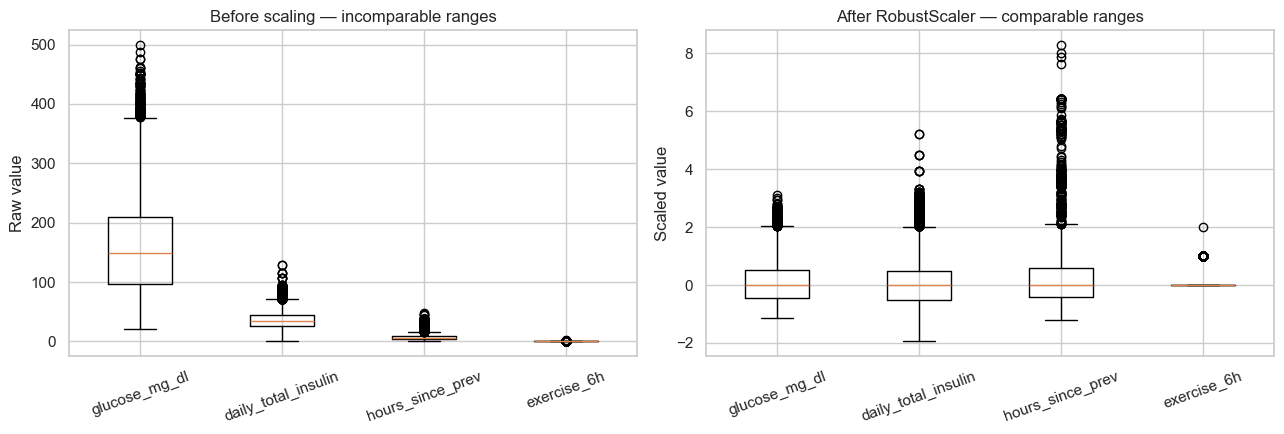

In [5]:
show = ["glucose_mg_dl", "daily_total_insulin", "hours_since_prev", "exercise_6h"]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].boxplot([GLU_out[c] for c in show], labels=show, vert=True)
axes[0].set_title("Before scaling — incomparable ranges")
axes[0].set_ylabel("Raw value")
axes[0].tick_params(axis="x", rotation=20)

axes[1].boxplot([GLU_scaled[c] for c in show], labels=show, vert=True)
axes[1].set_title("After RobustScaler — comparable ranges")
axes[1].set_ylabel("Scaled value")
axes[1].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.savefig(f"{FIGDIR}/scaling_before_after.png", dpi=150, bbox_inches="tight")
plt.show()

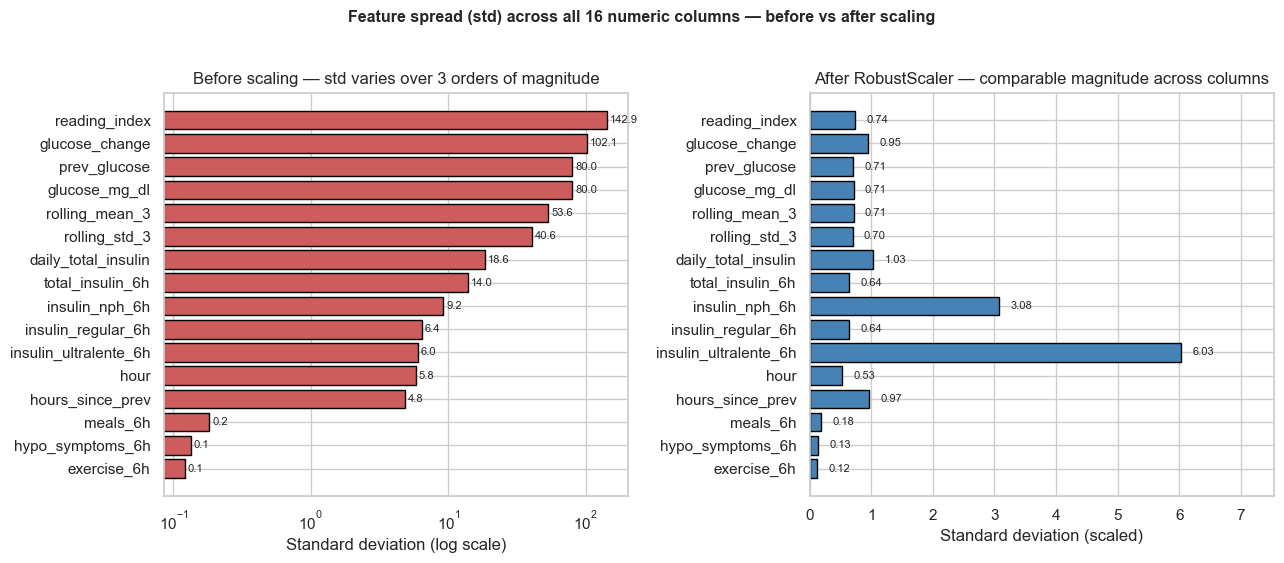

In [6]:
std_before = GLU_out[numeric_cols].std().sort_values(ascending=False)
std_after = GLU_scaled[numeric_cols].std().reindex(std_before.index)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

bars0 = axes[0].barh(std_before.index, std_before.values, color="indianred", edgecolor="black")
axes[0].set_xscale("log")
for b, v in zip(bars0, std_before.values):
    axes[0].text(v*1.05, b.get_y()+b.get_height()/2, f"{v:.1f}", va="center", fontsize=8)
axes[0].set_xlabel("Standard deviation (log scale)")
axes[0].set_title("Before scaling — std varies over 3 orders of magnitude")
axes[0].invert_yaxis()

bars1 = axes[1].barh(std_before.index, std_after.values, color="steelblue", edgecolor="black")
for b, v in zip(bars1, std_after.values):
    axes[1].text(v + std_after.max()*0.03, b.get_y()+b.get_height()/2, f"{v:.2f}", va="center", fontsize=8)
axes[1].set_xlabel("Standard deviation (scaled)")
axes[1].set_title("After RobustScaler — comparable magnitude across columns")
axes[1].set_xlim(0, std_after.max()*1.25)
axes[1].invert_yaxis()

fig.suptitle("Feature spread (std) across all 16 numeric columns — before vs after scaling",
             fontsize=11.5, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig(f"{FIGDIR}/scaling_std_comparison_before_after.png", dpi=150, bbox_inches="tight")
plt.show()

In [7]:
GLU_scaled.to_csv("results/outputs/04_scaled.csv", index=False)
print("saved:", GLU_scaled.shape)

saved: (13294, 30)
